## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/preprocessed.csv")
# convert to correct datatypes
print(df.info()) # cols and their dtypes

# convert datetime col
df["scraped_at"] = pd.to_datetime(df["scraped_at"])

# numeric cols that get interpreted as "object" because of nulls
columns = ["number_of_doors", "seating_capacity", "engine_displacement_cc"]
for col in columns:
    df[col] = df[col].astype("Int64")

# boolean cols
df["certified"] = df["certified"].map({"Certified": True, pd.NA: pd.NA}).astype("boolean")
df["featured"] = df["featured"].replace({"True": True, "False": False}).astype("boolean")
df.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2061 entries, 0 to 2060
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   listing_id              2061 non-null   int64  
 1   title                   2061 non-null   object 
 2   url                     2061 non-null   object 
 3   price_aed               2061 non-null   int64  
 4   price_rating            1060 non-null   object 
 5   year                    2061 non-null   int64  
 6   mileage_km              2061 non-null   int64  
 7   city                    2061 non-null   object 
 8   fuel_type               2058 non-null   object 
 9   transmission            2023 non-null   object 
 10  regional_specs          2059 non-null   object 
 11  body_style              2060 non-null   object 
 12  color                   2059 non-null   object 
 13  certified               2059 non-null   object 
 14  featured                1061 non-null   

,listing_id,title,url,price_aed,price_rating,year,mileage_km,city,fuel_type,transmission,...,seller_description,image_url,images,source_page,scraped_at,drive_type,number_of_doors,engine_displacement_cc,dealer,seating_capacity
0,2157629,Used KAIYI X7 1.6T (7 Seat) 2025,https://uae.yallamotor.com/used-cars/kaiyi/x7/...,49999,Good Deal,2025,21873,Dubai,Petrol,Automatic,...,Your 2025 Kaiyi X7 is waiting for you! Only fo...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.365000+00:00,Front-wheel drive,5,1600,KAVAK,<NA>
1,2154657,Used Volkswagen Tiguan 2.0 TSI Life 2022,https://uae.yallamotor.com/used-cars/volkswage...,70999,Great Deal,2022,31742,Dubai,Petrol,Automatic,...,Your 2022 Volkswagen Tiguan is waiting for you...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,All-wheel drive,5,2000,KAVAK,5
2,2154648,Used BMW 5 Series 530i M Sport 2019,https://uae.yallamotor.com/used-cars/bmw/5-ser...,65999,Great Deal,2019,105019,Dubai,Petrol,Automatic,...,Your 2019 BMW Series 5 is waiting for you! Onl...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Rear-wheel drive,4,2000,KAVAK,5
3,2156548,Used Nissan Sunny 1.5 S AUTO 2024,https://uae.yallamotor.com/used-cars/nissan/su...,29999,Good Deal,2024,78886,Dubai,Petrol,Automatic,...,Your 2024 Nissan Sunny is waiting for you! Onl...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Front-wheel drive,4,1500,KAVAK,5
4,2157632,Used Toyota Yaris Sedan 1.5 VVT-I E CVT 2023,https://uae.yallamotor.com/used-cars/toyota/ya...,41999,Fair Deal,2023,86129,Dubai,Petrol,Automatic,...,Your 2023 Toyota Yaris is waiting for you! Onl...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Front-wheel drive,4,1500,KAVAK,5
5,2157631,Used Toyota Yaris Sedan 1.5 VVT-I E CVT 2023,https://uae.yallamotor.com/used-cars/toyota/ya...,43999,NaN,2023,57518,Dubai,Petrol,Automatic,...,Your 2023 Toyota Yaris is waiting for you! Onl...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Front-wheel drive,4,1500,KAVAK,5
6,2157630,Used Nissan Xterra 2.5 2WD SE AUTO 2023,https://uae.yallamotor.com/used-cars/nissan/xt...,68999,Fair Deal,2023,69953,Dubai,Petrol,Automatic,...,Your 2023 Nissan Xterra is waiting for you! On...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Rear-wheel drive,5,2500,KAVAK,7
7,2157628,Used Jeep Wrangler 3.6 JL V6 SPORT 4WD AUTO 2021,https://uae.yallamotor.com/used-cars/jeep/wran...,100999,Fair Deal,2021,52000,Dubai,Petrol,Automatic,...,Your 2021 Jeep Wrangler is waiting for you! On...,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,All-wheel drive,3,3600,KAVAK,4
8,2151872,Used Mini Cooper S 2.0 COOPER S 2024,https://uae.yallamotor.com/used-cars/mini/coop...,95999,Great Deal,2024,8822,Dubai,Petrol,Automatic,...,Guaranteed Warranty | Zero down payment,https://ymimg1.b8cdn.com/resized/used_car/2026...,['https://ymimg1.b8cdn.com/resized/used_car/20...,https://uae.yallamotor.com/used-cars/co_kavak-...,2026-11-18 11:37:58.366000+00:00,Front-wheel drive,2,2000,KAVAK,4
9,2156870

## EDA

### Inventory Sizes

dealer
Cars24         704
KAVAK          552
AlbaCars       398
AutoCentral    207
CarSwitch      200
Name: count, dtype: int64


<Axes: title={'center': 'Number of YallaMotor Listings by Dealer'}, xlabel='Dealer', ylabel='Number of Listings'>

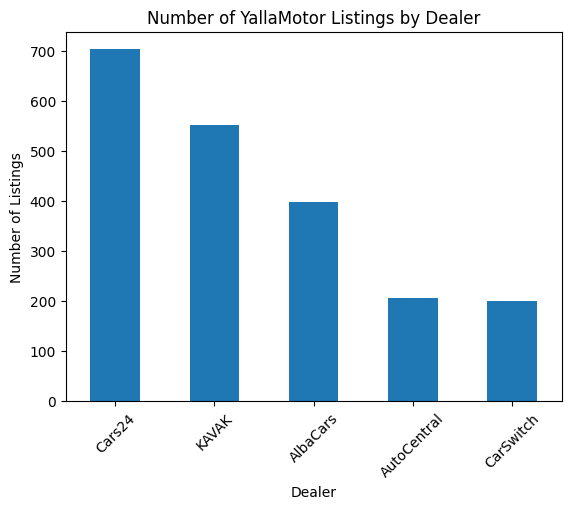

In [3]:
# compare inventory sizes (on yallamotors exclusively)
dealer_counts = df["dealer"].value_counts()
print(dealer_counts)
dealer_counts.plot(
    kind="bar",
    title="Number of YallaMotor Listings by Dealer",
    xlabel="Dealer",
    ylabel="Number of Listings",
    rot=45
)

### Brand Distributions

dealer      AlbaCars  AutoCentral  CarSwitch  Cars24  KAVAK
make                                                       
212                2            0          0       0      0
Alfa Romeo         6            0          2       4      1
Audi              39            0          4      11     15
BAIC               3            0          1       0      1
BMW               52            0         19      29     29
...              ...          ...        ...     ...    ...
Tesla              4            0          1       0      5
Toyota             4            2          3      52     38
Volkswagen        14            0          9      31     29
Volvo              9            0          2      10     12
Xpeng              0            0          1       0      0

[65 rows x 5 columns]


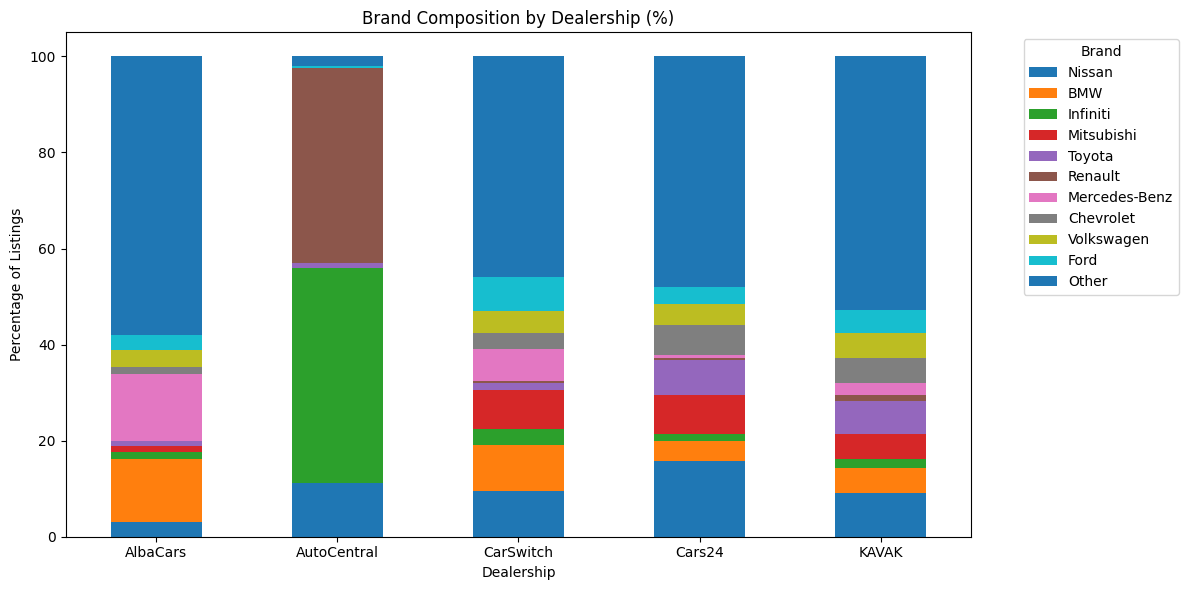


KAVAK
make
Nissan        50
Toyota        38
Mitsubishi    29
Volkswagen    29
BMW           29
Name: count, dtype: int64

Cars24
make
Nissan        111
Mitsubishi     56
Toyota         52
Geely          50
MG             44
Name: count, dtype: int64

CarSwitch
make
BMW              19
Nissan           19
Mitsubishi       16
Ford             14
Mercedes-Benz    13
Name: count, dtype: int64

AlbaCars
make
Mercedes-Benz    56
BMW              52
Audi             39
Land Rover       31
GMC              17
Name: count, dtype: int64

AutoCentral
make
Infiniti    93
Renault     84
Nissan      23
Mazda        2
Hyundai      2
Name: count, dtype: int64


In [4]:
# brand distribution per dealer
brand_counts = pd.crosstab(df["make"], df["dealer"])
print(brand_counts)

# Select the 10 most common brands overall
top_brands = df["make"].value_counts().head(10).index

# Count listings by dealer and brand
brand_counts = pd.crosstab(df["dealer"], df["make"])

# Convert counts to percentages of each dealer's total listings
brand_pct = brand_counts.div(brand_counts.sum(axis=1), axis=0) * 100

# Combine all remaining brands into "Other"
brand_pct["Other"] = brand_pct.drop(columns=top_brands).sum(axis=1)

# Plot
brand_pct[list(top_brands) + ["Other"]].plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Brand Composition by Dealership (%)")
plt.xlabel("Dealership")
plt.ylabel("Percentage of Listings")
plt.legend(title="Brand", bbox_to_anchor=(1.05, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


for dealer in df["dealer"].unique():
    print(f"\n{dealer}")
    print(
        df[df["dealer"] == dealer]["make"]
        .value_counts()
        .head(5)
    )

In [5]:

# 1. Number of unique models per dealership
unique_models = df.groupby("dealer")["make_model"].nunique()

print("Unique models per dealership:")
print(unique_models.sort_values(ascending=False))


# 2. Number of cars per model, for every dealership
model_counts = pd.crosstab(df["make_model"], df["dealer"])

display(model_counts)

KeyError: 'Column not found: make_model'

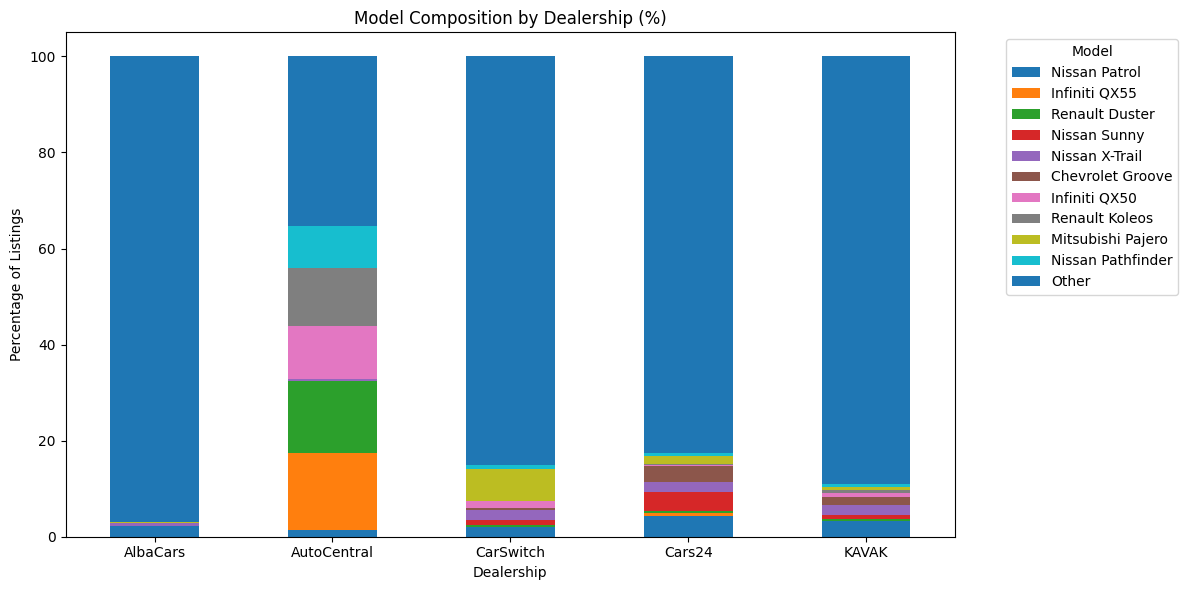


KAVAK
552
make_model
Nissan Patrol          18
Nissan X-Trail         12
Volkswagen Tiguan      11
Jeep Wrangler          11
Volkswagen Teramont     9
Name: count, dtype: int64

Cars24
704
make_model
Nissan Patrol         31
Nissan Sunny          28
Chevrolet Groove      23
Mitsubishi Attrage    23
Nissan Xterra         22
Name: count, dtype: int64

CarSwitch
200
make_model
Mitsubishi Pajero               13
Land Rover Range Rover Sport     7
Nissan Patrol                    4
Jeep Wrangler Unlimited          4
Nissan X-Trail                   4
Name: count, dtype: int64

AlbaCars
398
make_model
Audi Q8                         11
Nissan Patrol                    9
Land Rover Range Rover Sport     9
Mercedes-Benz C-Class            9
Land Rover Defender              9
Name: count, dtype: int64

AutoCentral
207
make_model
Infiniti QX55     33
Renault Duster    31
Renault Koleos    25
Renault Arkana    24
Infiniti QX50     23
Name: count, dtype: int64


In [ ]:
# brand-model drilldown

df["make_model"] = df["make"] + " " + df["model"]

# Count cars by model and dealership
model_counts = pd.crosstab(df["dealer"], df["make_model"])

# Select the 10 most common models overall
top_models = df["make_model"].value_counts().head(10).index

# Convert counts to percentages
model_pct = model_counts.div(model_counts.sum(axis=1), axis=0) * 100

# Combine remaining models into "Other"
model_pct["Other"] = model_pct.drop(columns=top_models).sum(axis=1)

# Plot
model_pct[list(top_models) + ["Other"]].plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Model Composition by Dealership (%)")
plt.xlabel("Dealership")
plt.ylabel("Percentage of Listings")
plt.legend(title="Model", bbox_to_anchor=(1.05, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Show top 5 models for each dealer
for dealer in df["dealer"].unique():
    print(f"\n{dealer}")
    print(
        df[df["dealer"] == dealer]["make_model"]
        .value_counts()
        .head(5)
    )


### Car Age Distributions

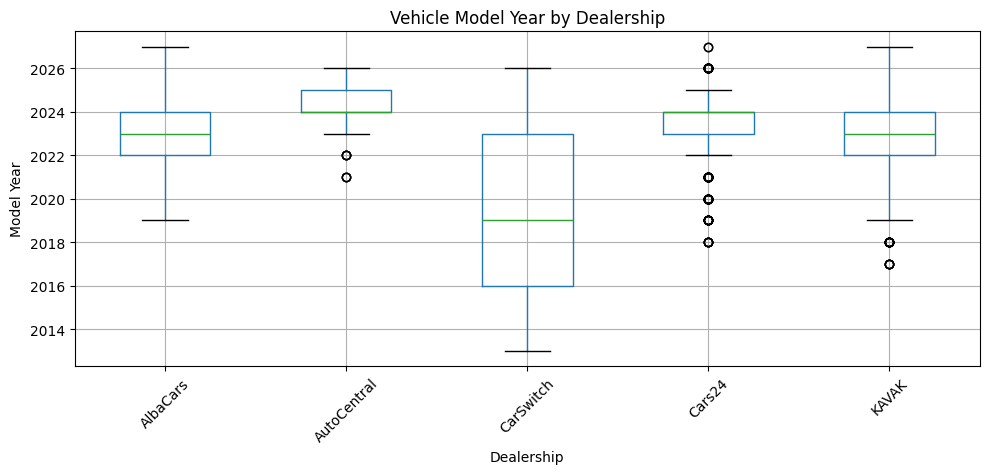

In [ ]:
df.boxplot(column="year", by="dealer", figsize=(10, 5))

plt.title("Vehicle Model Year by Dealership")
plt.suptitle("")
plt.xlabel("Dealership")
plt.ylabel("Model Year")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
print(df.groupby("dealer")["year"].agg(["count", "min", "median", "mean", "max"]).round(1))

             count   min  median    mean   max
dealer                                        
AlbaCars       398  2019  2023.0  2023.0  2027
AutoCentral    207  2021  2024.0  2024.1  2026
CarSwitch      200  2013  2019.0  2019.3  2026
Cars24         704  2018  2024.0  2023.4  2027
KAVAK          552  2017  2023.0  2023.0  2027


               count   median
year_group                   
2020 or older     66  46499.0
2021–2023        235  68999.0
2024 or newer    251  83499.0


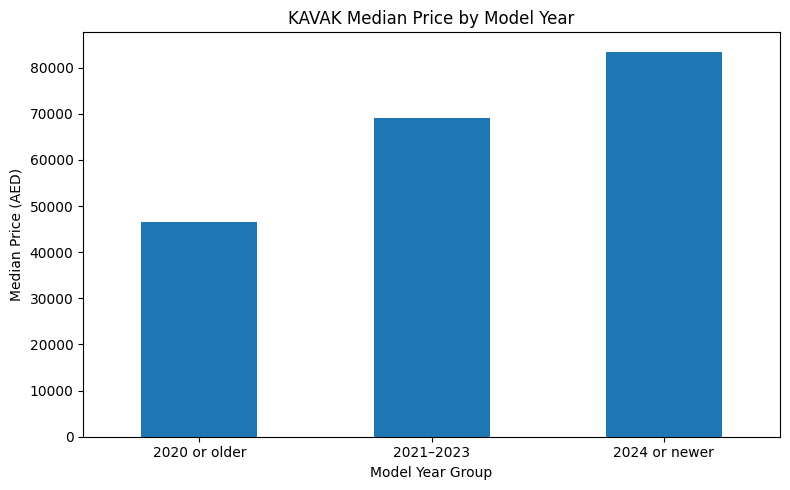

In [ ]:
# Select KAVAK cars
kavak = df[df["dealer"] == "KAVAK"].copy()
# Divide cars into model-year groups
kavak["year_group"] = pd.cut(
    kavak["year"],
    bins=[0, 2020, 2023, 2030],
    labels=["2020 or older", "2021–2023", "2024 or newer"]
)
# Calculate median price and number of cars
age_prices = kavak.groupby("year_group", observed=True)["price_aed"].agg(["count", "median"])
print(age_prices)

### Mileage Distribution

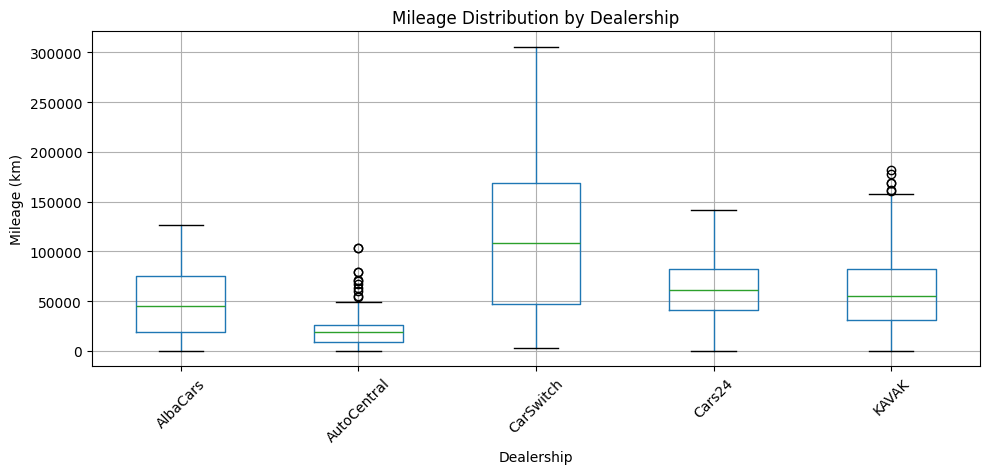

In [ ]:
df.boxplot(column="mileage_km", by="dealer", figsize=(10, 5))

plt.title("Mileage Distribution by Dealership")
plt.suptitle("")
plt.xlabel("Dealership")
plt.ylabel("Mileage (km)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
print(df.groupby("dealer")["mileage_km"].agg(["min", "median", "mean", "max"]).round(0))

              min    median      mean     max
dealer                                       
AlbaCars       18   45500.0   48550.0  127000
AutoCentral     5   18508.0   20293.0  103544
CarSwitch    3000  108600.0  113941.0  305800
Cars24         20   61030.0   62361.0  141805
KAVAK          14   55008.0   59795.0  182000


dealer
AutoCentral    10599.0
AlbaCars       14833.0
CarSwitch      16071.0
KAVAK          19916.0
Cars24         24733.0
Name: annual_mileage, dtype: float64


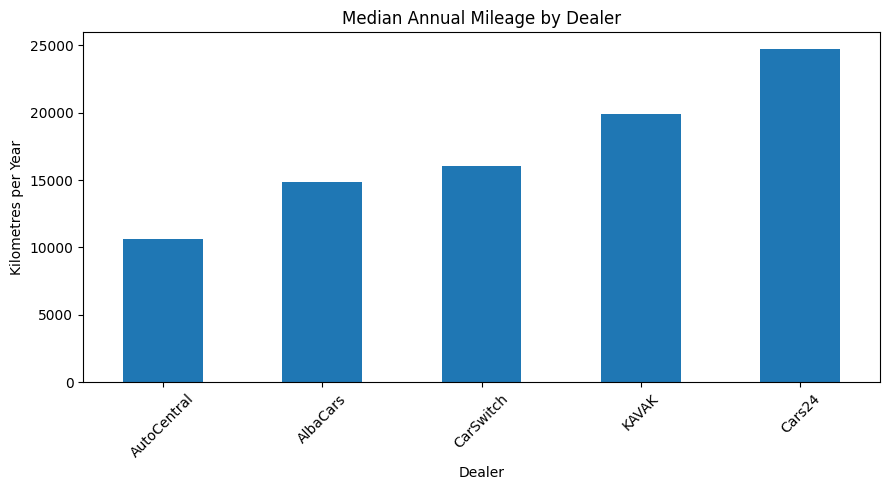

In [ ]:
# annual mileage
# Calculate vehicle age
df["vehicle_age"] = df["scraped_at"].dt.year - df["year"]

# Calculate annual mileage
df["annual_mileage"] = np.where(
    df["vehicle_age"] > 0,
    df["mileage_km"] / df["vehicle_age"],
    np.nan
)

# Median annual mileage by dealer
annual = df.groupby("dealer")["annual_mileage"].median().sort_values()
print(annual.round(0))

# Visualize
annual.plot(kind="bar", figsize=(9, 5))
plt.title("Median Annual Mileage by Dealer")
plt.ylabel("Kilometres per Year")
plt.xlabel("Dealer")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


dealer   Cars24     KAVAK
year                     
2020    98458.0  106957.0
2021    95221.0   95017.0
2022    82165.0   74634.0
2023    71962.0   66545.0
2024    55882.0   42905.0
2025    36568.0   26286.0

Cars per Year
dealer  Cars24  KAVAK
year                 
2020        31     29
2021        33     44
2022        47     68
2023       192    123
2024       220    125
2025       129     90


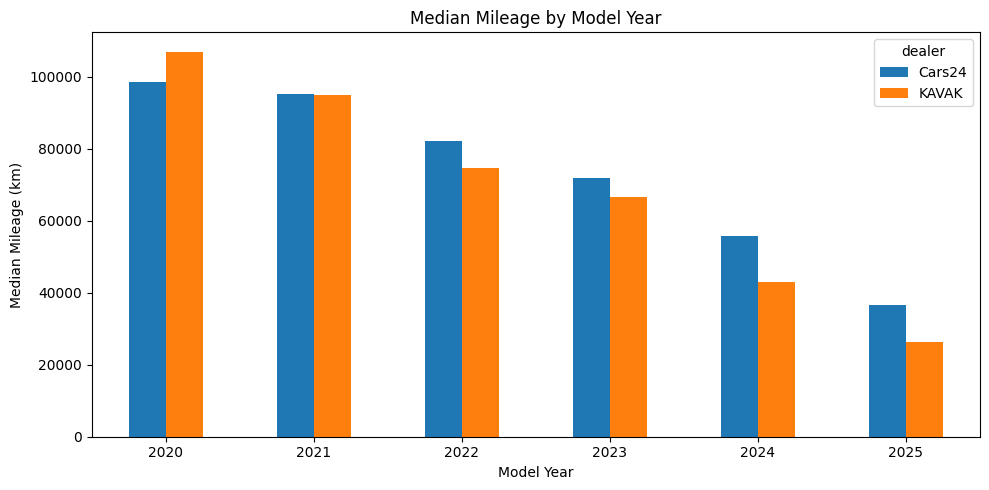

In [ ]:
# compare mileage by year group
# Select both dealers and model years
cars = df[
    (df["dealer"].isin(["KAVAK", "Cars24"])) &
    (df["year"].between(2020, 2025))
]

# Median mileage for each model year
year_mileage = cars.groupby(["year", "dealer"])["mileage_km"].median().unstack()

print(year_mileage.round(0))


# Count cars for each model year and dealer
print('\nCars per Year')
year_counts = cars.groupby(["year", "dealer"]).size().unstack()
print(year_counts)


# Visualize
year_mileage.plot(kind="bar", figsize=(10, 5))
plt.title("Median Mileage by Model Year")
plt.xlabel("Model Year")
plt.ylabel("Median Mileage (km)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Price Distribution

In [ ]:
print(df.groupby("dealer")["price_aed"].agg(["min", "median", "mean", "max"]).round(0))

               min    median      mean      max
dealer                                         
AlbaCars     44999  151499.0  182047.0  1164999
AutoCentral  36000  108000.0  120453.0   435000
CarSwitch     9000   55000.0   78676.0   420000
Cars24       19099   64999.0   80502.0   301999
KAVAK        13999   69499.0   85720.0   349999


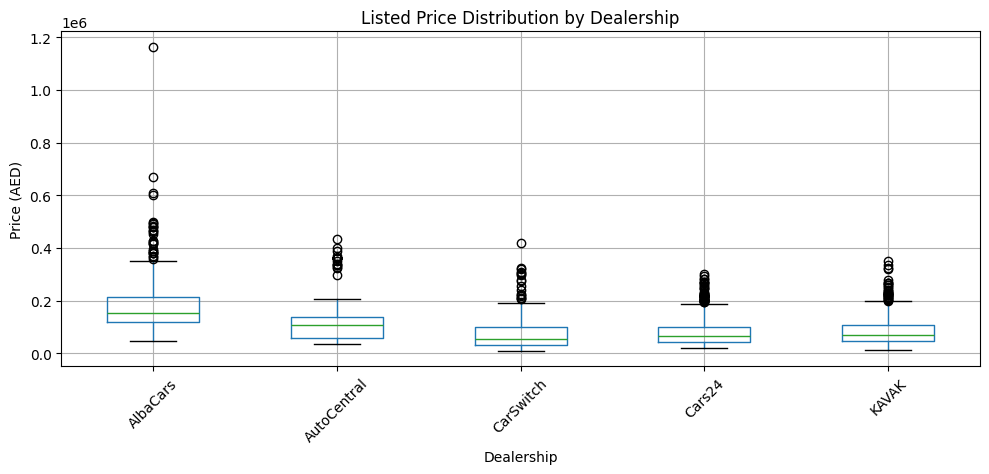

In [ ]:
df.boxplot(column="price_aed", by="dealer", figsize=(10, 5))

plt.title("Listed Price Distribution by Dealership")
plt.suptitle("")
plt.xlabel("Dealership")
plt.ylabel("Price (AED)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

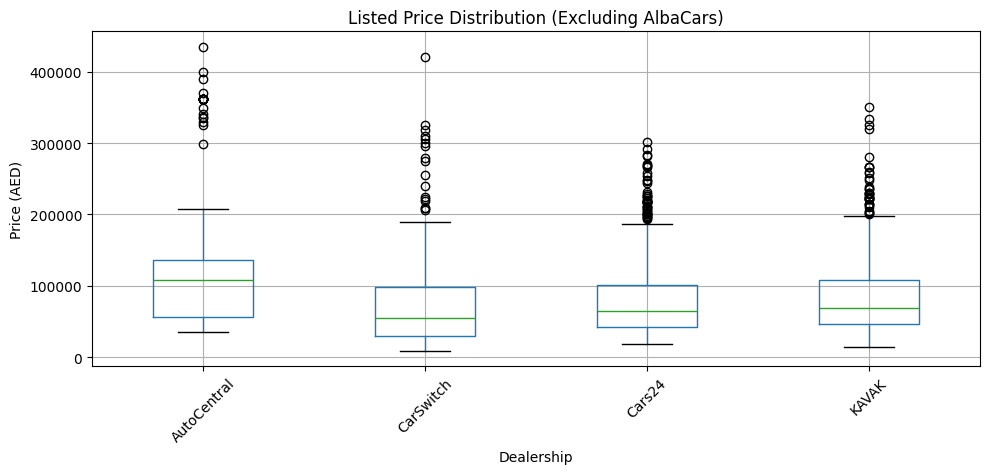

In [ ]:
df_no_alba = df[df["dealer"] != "AlbaCars"]

df_no_alba.boxplot(column="price_aed", by="dealer", figsize=(10, 5))
plt.title("Listed Price Distribution (Excluding AlbaCars)")
plt.suptitle("")
plt.xlabel("Dealership")
plt.ylabel("Price (AED)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Number of cars:
price_bracket  Below 30k  30–50k  50–70k  70–100k  100–150k  150k+
dealer                                                            
AlbaCars               0       1       7       49       142    199
AutoCentral            0      21      60       19        71     36
CarSwitch             48      45      26       32        25     24
Cars24                72     181     129      142       101     79
KAVAK                 37     140     107      109        90     69

Percentages:
price_bracket  Below 30k  30–50k  50–70k  70–100k  100–150k  150k+
dealer                                                            
AlbaCars             0.0     0.3     1.8     12.3      35.7   50.0
AutoCentral          0.0    10.1    29.0      9.2      34.3   17.4
CarSwitch           24.0    22.5    13.0     16.0      12.5   12.0
Cars24              10.2    25.7    18.3     20.2      14.3   11.2
KAVAK                6.7    25.4    19.4     19.7      16.3   12.5


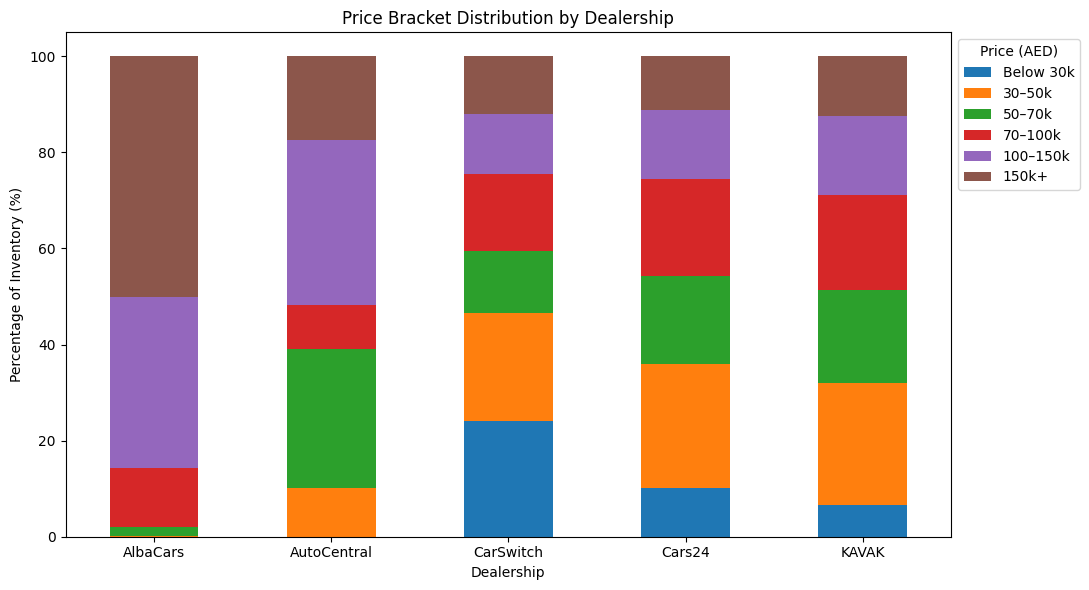

In [ ]:
# Define price brackets (AED)
bins = [0, 30000, 50000, 70000, 100000, 150000, float("inf")]
labels = ["Below 30k", "30–50k", "50–70k", "70–100k", "100–150k", "150k+"]

df["price_bracket"] = pd.cut(
    df["price_aed"],
    bins=bins,
    labels=labels,
    right=False
)

# Count listings per bracket
counts = pd.crosstab(df["dealer"], df["price_bracket"])
print("Number of cars:")
print(counts)

# Calculate percentage within each dealership
percentages = counts.div(counts.sum(axis=1), axis=0) * 100
print("\nPercentages:")
print(percentages.round(1))

# Visualize
percentages.plot(kind="bar", stacked=True, figsize=(11, 6))

plt.title("Price Bracket Distribution by Dealership")
plt.xlabel("Dealership")
plt.ylabel("Percentage of Inventory (%)")
plt.xticks(rotation=0)
plt.legend(title="Price (AED)", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()


### Body type, fuel type, and transmission type distr.

body_style   Convertible     Coupe  Hatchback  Minivan / Van  Pickup Truck  \
dealer                                                                       
AlbaCars        0.251889  4.785894   3.526448       0.503778      5.541562   
AutoCentral     0.000000  0.483092   0.000000       0.000000      0.000000   
CarSwitch       1.000000  3.000000   6.500000       0.000000      1.500000   
Cars24          0.426136  1.562500   4.687500       0.142045      0.426136   
KAVAK           0.543478  1.449275   7.246377       1.086957      1.992754   

body_style   SUV / Crossover      Sedan     Wagon  
dealer                                             
AlbaCars           68.010076  17.128463  0.251889  
AutoCentral        94.685990   4.830918  0.000000  
CarSwitch          68.500000  19.500000  0.000000  
Cars24             73.437500  19.318182  0.000000  
KAVAK              72.463768  15.217391  0.000000  


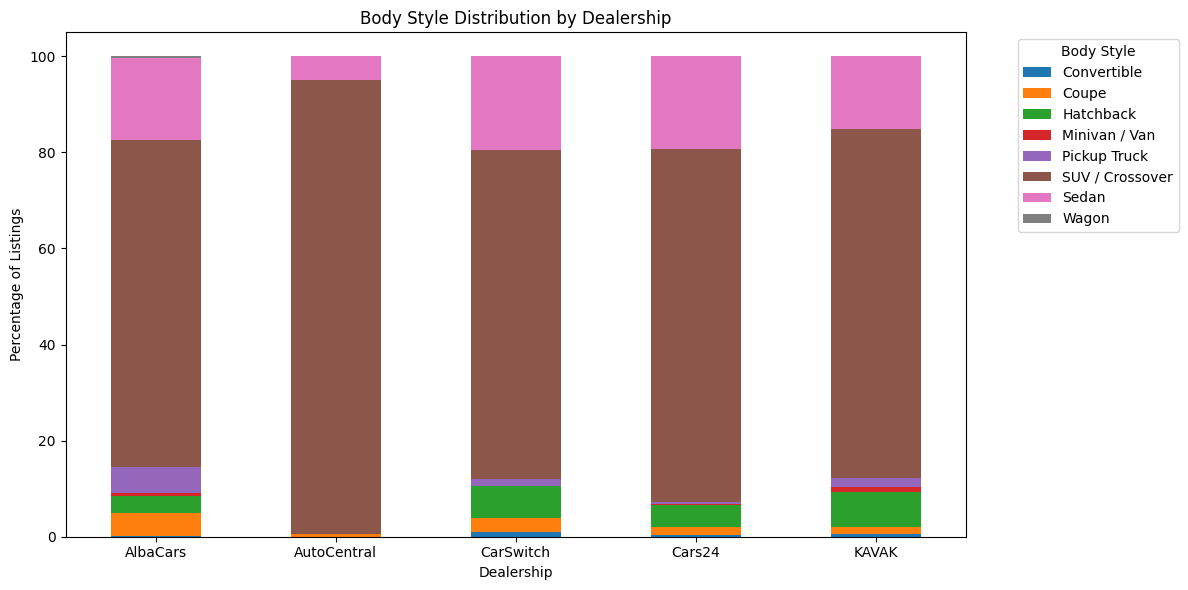

In [ ]:
# body type
body_pct = pd.crosstab(df["dealer"], df["body_style"], normalize="index") * 100
print(body_pct)

body_pct.plot(kind="bar", stacked=True, figsize=(12, 6))
plt.title("Body Style Distribution by Dealership")
plt.xlabel("Dealership")
plt.ylabel("Percentage of Listings")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05, 1), title="Body Style")
plt.tight_layout()
plt.show()

fuel_type    Electric    Hybrid      Petrol
dealer                                     
AlbaCars     4.030227  3.274559   92.695214
AutoCentral  0.000000  0.000000  100.000000
CarSwitch    1.515152  1.010101   97.474747
Cars24       0.000000  0.852273   99.147727
KAVAK        1.449275  0.000000   98.550725


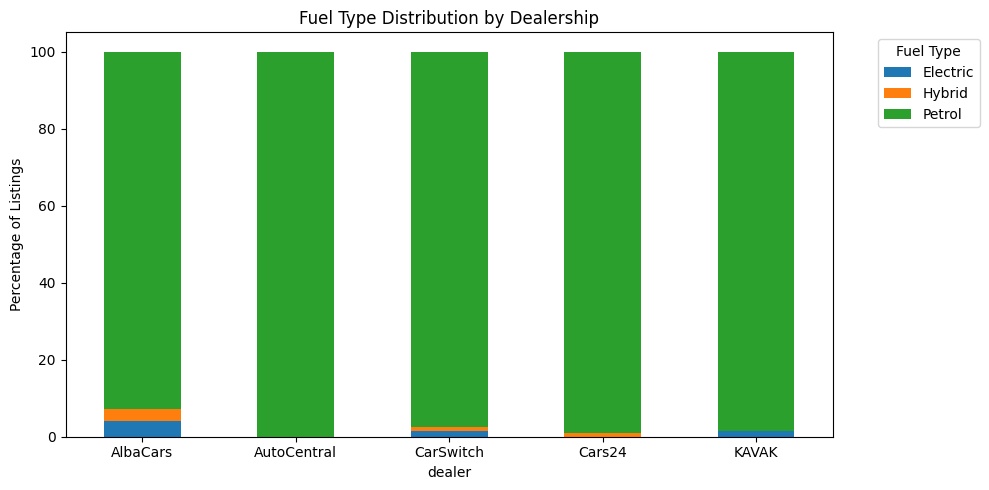

In [ ]:
# fuel type
fuel_pct = pd.crosstab(df["dealer"], df["fuel_type"], normalize="index") * 100
print(fuel_pct)

fuel_pct.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Fuel Type Distribution by Dealership")
plt.ylabel("Percentage of Listings")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05, 1), title="Fuel Type")
plt.tight_layout()
plt.show()